# Detección de Fallas en Sensores IoT Industriales — Entrega Final
## Diplomado en Ciencia de Datos y Análisis Avanzado — UTN FRBA

**Dataset:** AI4I 2020 Predictive Maintenance (UCI ML Repository, CC BY 4.0)
**Autores:** Juan Marcelo Saumell, Axel Carcia, Juan Ignacio Figueiras, Luis Ignacio Alaniz Bellotti, Santino Martins

---

## Metodología: CRISP-DM

| Fase | Dónde está en el proyecto |
|---|---|
| 1. Comprensión del negocio | Problema, KPI y benchmark de mantenimiento reactivo (informe §1-2) |
| 2. Comprensión de los datos | Notebook §2-3: EDA, nulos, outliers, consistencia del target |
| 3. Preparación de los datos | §4: IDs, Type ordinal, Temp_delta, Power, Strain |
| 4. Modelado | §5-8: baseline, LR/RF/XGBoost, pesos vs SMOTE, Isolation Forest |
| 5. Evaluación | §9-11: umbral por costos, test, importancia de variables |
| 6. Despliegue (propuesta) | Alertas por máquina; no se despliega porque la consigna no lo exige |

## 1. Setup e importación de datos

In [ ]:
# Solo Colab: instala las dependencias que no vienen preinstaladas.
# En local usar: pip install -r requirements.txt
%pip install -q ucimlrepo xgboost imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print("✅ Librerías cargadas")

✅ Librerías cargadas


In [3]:
from pathlib import Path

# Descarga desde UCI ML Repository (id=601) con copia local para reproducibilidad
DATA_PATH = Path("ai4i2020.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    dataset = fetch_ucirepo(id=601)
    df = dataset.data.original.copy()  # 14 columnas, incluye UID y Product ID
    df.to_csv(DATA_PATH, index=False)

print(f"Shape: {df.shape}")
df.head()

Shape: (10000, 14)


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Exploración inicial del dataset

Verificamos estructura, tipos de datos, nulos y estadísticas descriptivas.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UID                  10000 non-null  int64  
 1   Product ID           10000 non-null  object 
 2   Type                 10000 non-null  object 
 3   Air temperature      10000 non-null  float64
 4   Process temperature  10000 non-null  float64
 5   Rotational speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool wear            10000 non-null  int64  
 8   Machine failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


In [5]:
df.describe()

,UID,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
# Verificar nulos
print("=== Valores nulos por columna ===")
print(df.isnull().sum())
print(f"\nTotal nulos: {df.isnull().sum().sum()}")

=== Valores nulos por columna ===
UID                    0
Product ID             0
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64

Total nulos: 0


In [7]:
# Distribución del target (Machine failure)
print("=== Distribución de clases ===")
print(df['Machine failure'].value_counts())
print(f"\nPorcentaje de fallas: {df['Machine failure'].mean()*100:.2f}%")

=== Distribución de clases ===
Machine failure
0    9661
1     339
Name: count, dtype: int64

Porcentaje de fallas: 3.39%


In [8]:
# Consistencia del target vs modos de falla
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
any_mode = df[failure_modes].sum(axis=1) > 0

print("Falla sin ningún modo marcado:", ((df['Machine failure'] == 1) & ~any_mode).sum())
print("Modo marcado sin falla registrada:", ((df['Machine failure'] == 0) & any_mode).sum())
print("Filas con RNF (falla aleatoria, no predecible):", df['RNF'].sum())
print("Fallas con más de un modo:", (df[failure_modes].sum(axis=1) > 1).sum())

Falla sin ningún modo marcado: 9
Modo marcado sin falla registrada: 18
Filas con RNF (falla aleatoria, no predecible): 19
Fallas con más de un modo: 24


**Decisión: se mantiene `Machine failure` como target.**

- 9 fallas no tienen modo asociado: se conservan como fallas (posible ruido de etiqueta).
- 18 registros con RNF=1 figuran sin falla; no afectan al target.
- RNF es aleatoria por diseño (19 casos): no es predecible y acota el recall máximo.

## 3. Análisis Exploratorio de Datos (EDA)

### 3.1 Distribución del target y modos de falla

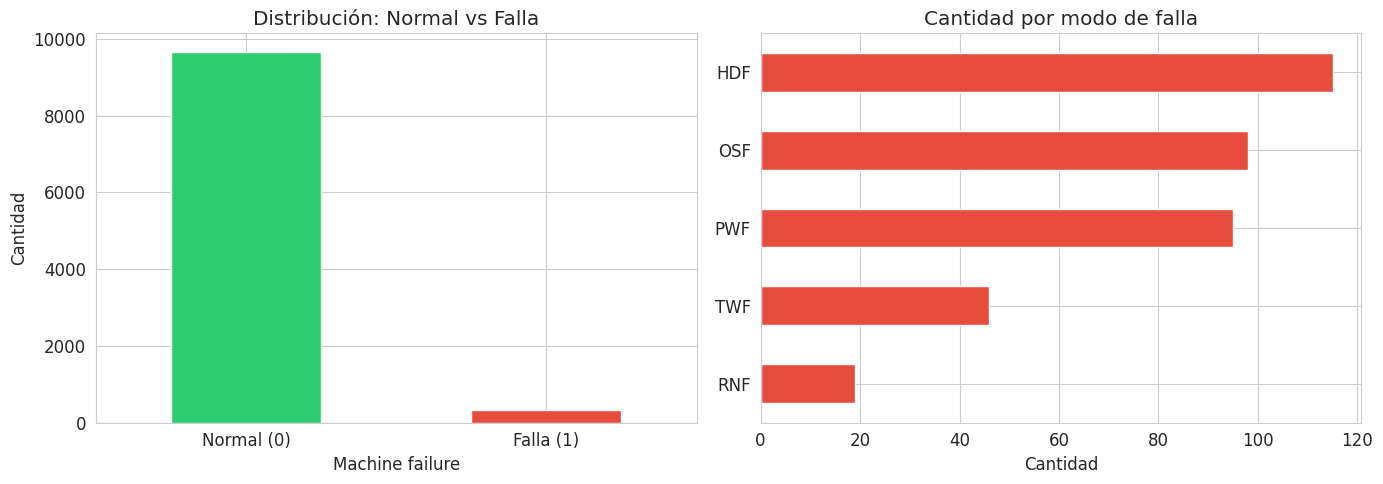

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución general de fallas
ax = axes[0]
df['Machine failure'].value_counts().plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'])
ax.set_title('Distribución: Normal vs Falla')
ax.set_xticklabels(['Normal (0)', 'Falla (1)'], rotation=0)
ax.set_ylabel('Cantidad')

# Modos de falla
ax = axes[1]
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
mode_counts = df[failure_modes].sum().sort_values(ascending=True)
mode_counts.plot(kind='barh', ax=ax, color='#e74c3c')
ax.set_title('Cantidad por modo de falla')
ax.set_xlabel('Cantidad')

plt.tight_layout()
plt.show()

### 3.2 Distribución de variables numéricas

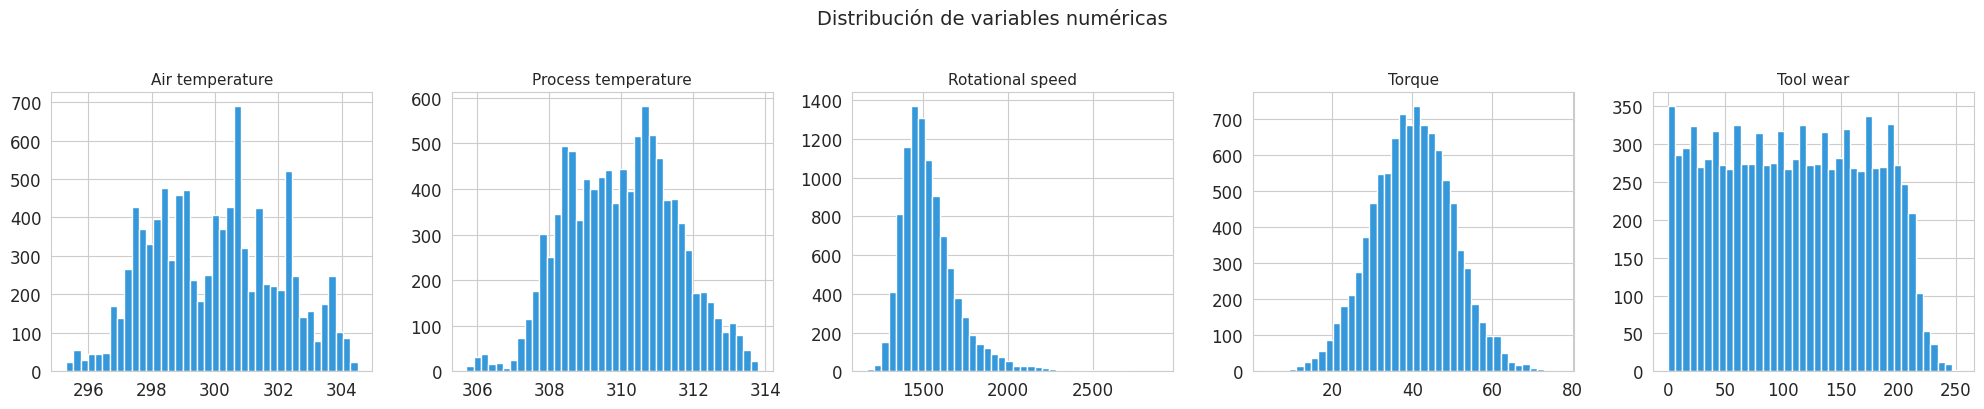

In [10]:
num_cols = ['Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear']

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for i, col in enumerate(num_cols):
    df[col].hist(bins=40, ax=axes[i], color='#3498db', edgecolor='white')
    axes[i].set_title(col, fontsize=11)

plt.suptitle('Distribución de variables numéricas', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Boxplots — Detección de outliers

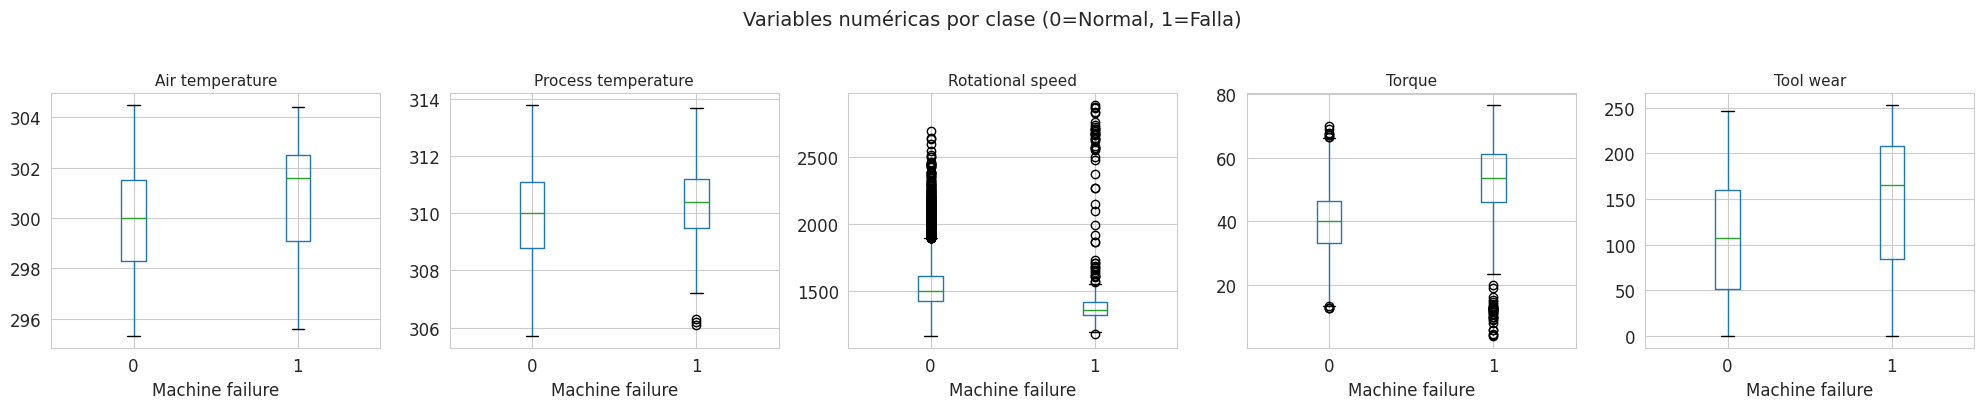

In [11]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='Machine failure', ax=axes[i])
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('Machine failure')

plt.suptitle('Variables numéricas por clase (0=Normal, 1=Falla)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Matriz de correlación

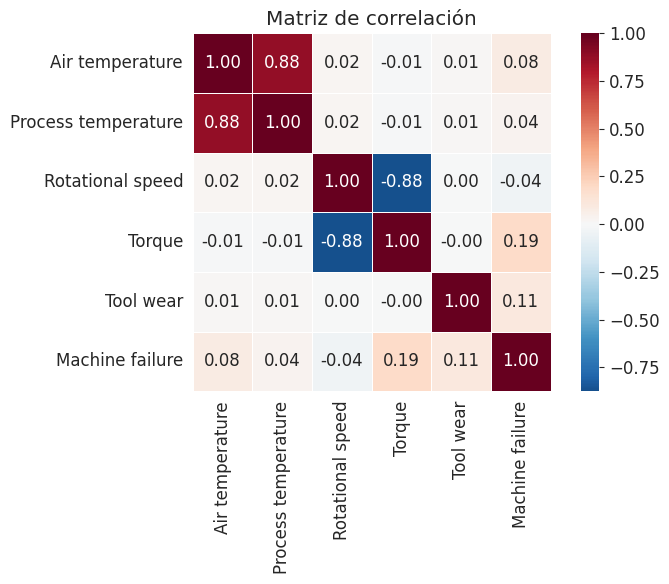

In [12]:
corr_cols = num_cols + ['Machine failure']
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

### 3.5 Tasa de falla por tipo de producto

      Tasa de falla  Total  Fallas
Type                              
H              2.09   1003      21
L              3.92   6000     235
M              2.77   2997      83


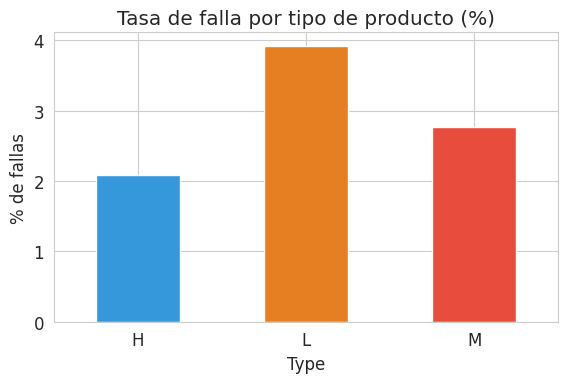

In [13]:
failure_by_type = df.groupby('Type')['Machine failure'].agg(['mean', 'count', 'sum'])
failure_by_type.columns = ['Tasa de falla', 'Total', 'Fallas']
failure_by_type['Tasa de falla'] = (failure_by_type['Tasa de falla'] * 100).round(2)
print(failure_by_type)

fig, ax = plt.subplots(figsize=(6, 4))
failure_by_type['Tasa de falla'].plot(kind='bar', ax=ax, color=['#3498db', '#e67e22', '#e74c3c'])
ax.set_title('Tasa de falla por tipo de producto (%)')
ax.set_ylabel('% de fallas')
ax.set_xticklabels(failure_by_type.index, rotation=0)
plt.tight_layout()
plt.show()

### 3.6 Outliers — Resumen cuantitativo (IQR)

In [14]:
def outlier_summary(dataframe, columns):
    records = []
    for col in columns:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        n_out = ((dataframe[col] < lower) | (dataframe[col] > upper)).sum()
        records.append({
            'Variable': col,
            'Q1': round(Q1, 2),
            'Q3': round(Q3, 2),
            'IQR': round(IQR, 2),
            'Límite inf': round(lower, 2),
            'Límite sup': round(upper, 2),
            'Outliers': n_out,
            '% Outliers': round(n_out / len(dataframe) * 100, 2)
        })
    return pd.DataFrame(records)

outlier_df = outlier_summary(df, num_cols)
outlier_df

,Variable,Q1,Q3,IQR,Límite inf,Límite sup,Outliers,% Outliers
0,Air temperature,298.3,301.5,3.2,293.50,306.30,0,0.00
1,Process temperature,308.8,311.1,2.3,305.35,314.55,0,0.00
2,Rotational speed,1423.0,1612.0,189.0,1139.50,1895.50,418,4.18
3,Torque,33.2,46.8,13.6,12.80,67.20,69,0.69
4,Tool wear,53.0,162.0,109.0,-110.50,325.50,0,0.00


## 4. Preprocesamiento

Decisiones de limpieza aplicadas y pendientes para la entrega final.

- **Outliers:** se conservan. Los valores altos de `Rotational speed` (4.18%) son físicamente posibles y concentran fallas PWF/OSF; eliminarlos quitaría señal.
- **Features de dominio:** `Power` [W] = Torque × velocidad angular y `Strain` = Tool wear × Torque. Se comparan modelos con y sin ellas (sección 6).
- **Type:** codificación ordinal L<M<H. Se comparó contra one-hot en CV (sección 5.1): empate técnico, se elige ordinal por simplicidad y por respetar el orden de calidad.

In [15]:
# Eliminar columnas identificadoras (sin valor predictivo)
df_clean = df.drop(columns=['UID', 'Product ID'])

# Codificar Type como ordinal (L=0, M=1, H=2)
type_map = {'L': 0, 'M': 1, 'H': 2}
df_clean['Type'] = df_clean['Type'].map(type_map)

# Feature engineering
df_clean['Temp_delta'] = df_clean['Process temperature'] - df_clean['Air temperature']
df_clean['Power'] = df_clean['Torque'] * df_clean['Rotational speed'] * 2 * np.pi / 60
df_clean['Strain'] = df_clean['Tool wear'] * df_clean['Torque']

# Dos sets de features: sin y con las variables de dominio
FEATURES = {
    'base': ['Type', 'Air temperature', 'Process temperature', 'Rotational speed',
             'Torque', 'Tool wear', 'Temp_delta'],
}
FEATURES['dominio'] = FEATURES['base'] + ['Power', 'Strain']

# Los modos de falla se excluyen: son parte del target
X = df_clean[FEATURES['dominio']]
y = df_clean['Machine failure']

print(f"Features base: {len(FEATURES['base'])} | con dominio: {len(FEATURES['dominio'])}")
print(f"Target - Fallas: {y.sum()} ({y.mean()*100:.2f}%)")
X.head()

Features base: 7 | con dominio: 9
Target - Fallas: 339 (3.39%)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Temp_delta,Power,Strain
0,1,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,0,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,0,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,0,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,0,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0


## 5. Baseline — Regresión Logística

Establecemos un primer modelo reproducible como punto de referencia.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Holdout 80/20 estratificado: el test queda aislado hasta la evaluación final
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Pipeline: escalado + regresión logística balanceada
baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# Stratified 5-Fold CV solo sobre train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'f1': 'f1', 'precision': 'precision', 'recall': 'recall',
           'pr_auc': 'average_precision'}

results = cross_validate(baseline, X_train[FEATURES['base']], y_train, cv=cv, scoring=scoring)

print("=== Baseline: Regresión Logística (Stratified 5-Fold CV sobre train) ===")
for name in scoring:
    vals = results[f'test_{name}']
    print(f"{name:<10} {vals.mean():.4f} ± {vals.std():.4f}")

=== Baseline: Regresión Logística (Stratified 5-Fold CV sobre train) ===
f1         0.2326 ± 0.0093
precision  0.1361 ± 0.0045
recall     0.8044 ± 0.0708
pr_auc     0.4424 ± 0.0266


### 5.1 Codificación de `Type`: ordinal vs one-hot

Mismo baseline y mismos folds; solo cambia la codificación.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

num_features = [c for c in FEATURES['base'] if c != 'Type']
baseline_onehot = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first'), ['Type']),
    ])),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

comparacion = {}
for name, model in [('Ordinal', baseline), ('One-hot', baseline_onehot)]:
    r = cross_validate(model, X_train[FEATURES['base']], y_train, cv=cv, scoring=scoring)
    comparacion[name] = {k: f"{r[f'test_{k}'].mean():.4f} ± {r[f'test_{k}'].std():.4f}"
                         for k in scoring}

pd.DataFrame(comparacion).T

,f1,precision,recall,pr_auc
Ordinal,0.2326 ± 0.0093,0.1361 ± 0.0045,0.8044 ± 0.0708,0.4424 ± 0.0266
One-hot,0.2339 ± 0.0103,0.1369 ± 0.0053,0.8044 ± 0.0668,0.4402 ± 0.0294


Las diferencias son menores que la variación entre folds: empate técnico. Se mantiene la codificación ordinal.

              precision    recall  f1-score   support

      Normal       0.99      0.82      0.90      7729
       Falla       0.14      0.80      0.23       271

    accuracy                           0.82      8000
   macro avg       0.56      0.81      0.57      8000
weighted avg       0.96      0.82      0.88      8000



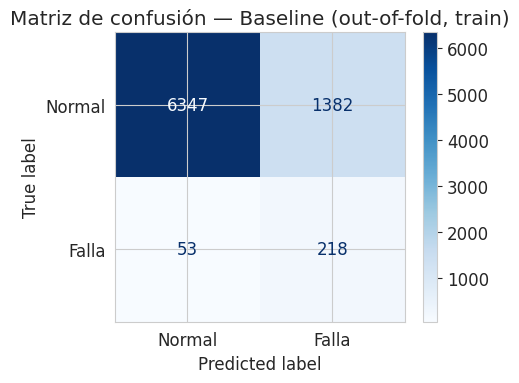

In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Predicciones out-of-fold sobre train (el test no se toca en la pre-entrega)
y_pred_oof = cross_val_predict(baseline, X_train[FEATURES['base']], y_train, cv=cv)

print(classification_report(y_train, y_pred_oof, target_names=['Normal', 'Falla']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_oof,
    display_labels=['Normal', 'Falla'],
    cmap='Blues', ax=ax
)
ax.set_title('Matriz de confusión — Baseline (out-of-fold, train)')
plt.tight_layout()
plt.show()

## 6. Modelado: comparación de algoritmos

Se comparan Regresión Logística, Random Forest y XGBoost, cada uno con:

- dos sets de features (`base` y `dominio`),
- dos manejos del desbalance (pesos de clase y SMOTE dentro de cada fold).

Los hiperparámetros se buscan con `RandomizedSearchCV` (20 combinaciones, 5 folds) solo sobre train, optimizando **PR-AUC**. El test sigue aislado.

In [19]:
from scipy.stats import loguniform
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

SEED = 42
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


def make_model(name, balance):
    """Devuelve el clasificador; con balance='pesos' penaliza más los errores en fallas."""
    weighted = balance == 'pesos'
    if name == 'Regresión Logística':
        return LogisticRegression(class_weight='balanced' if weighted else None,
                                  max_iter=2000, random_state=SEED)
    if name == 'Random Forest':
        return RandomForestClassifier(class_weight='balanced' if weighted else None,
                                      n_jobs=-1, random_state=SEED)
    return XGBClassifier(scale_pos_weight=pos_weight if weighted else 1,
                         eval_metric='aucpr', n_jobs=-1, random_state=SEED)


PARAMS = {
    'Regresión Logística': {'clf__C': loguniform(1e-3, 1e2)},
    'Random Forest': {
        'clf__n_estimators': [200, 400],
        'clf__max_depth': [None, 5, 10, 20],
        'clf__min_samples_leaf': [1, 2, 5, 10],
        'clf__max_features': ['sqrt', 0.5],
    },
    'XGBoost': {
        'clf__n_estimators': [200, 400, 600],
        'clf__max_depth': [3, 4, 6, 8],
        'clf__learning_rate': loguniform(0.01, 0.3),
        'clf__subsample': [0.7, 0.85, 1.0],
        'clf__colsample_bytree': [0.7, 0.85, 1.0],
        'clf__min_child_weight': [1, 3, 5],
    },
}


def make_pipeline(name, balance):
    steps = [('scaler', StandardScaler())]
    if balance == 'smote':
        steps.append(('smote', SMOTE(random_state=SEED)))
    steps.append(('clf', make_model(name, balance)))
    return ImbPipeline(steps)

In [ ]:
import time

resultados, mejores = [], {}
for name in PARAMS:
    for feats in FEATURES:
        for balance in ['pesos', 'smote']:
            t0 = time.time()
            search = RandomizedSearchCV(
                make_pipeline(name, balance), PARAMS[name], n_iter=20,
                scoring=scoring, refit='pr_auc', cv=cv, n_jobs=-1, random_state=SEED,
            )
            search.fit(X_train[FEATURES[feats]], y_train)
            i, cvr = search.best_index_, search.cv_results_
            resultados.append({
                'Modelo': name, 'Features': feats, 'Desbalance': balance,
                **{m: cvr[f'mean_test_{m}'][i] for m in scoring},
                'PR-AUC std': cvr['std_test_pr_auc'][i],
                'Segundos': round(time.time() - t0),
            })
            mejores[(name, feats, balance)] = search.best_estimator_
            print(f"{name:<20} {feats:<8} {balance:<6} PR-AUC={cvr['mean_test_pr_auc'][i]:.4f}")

tabla = pd.DataFrame(resultados).sort_values('pr_auc', ascending=False).reset_index(drop=True)
tabla.round(4)

Regresión Logística  base     pesos  PR-AUC=0.4426
Regresión Logística  base     smote  PR-AUC=0.4372
Regresión Logística  dominio  pesos  PR-AUC=0.4863
Regresión Logística  dominio  smote  PR-AUC=0.4804
Random Forest        base     pesos  PR-AUC=0.8140
Random Forest        base     smote  PR-AUC=0.7983
Random Forest        dominio  pesos  PR-AUC=0.8984
Random Forest        dominio  smote  PR-AUC=0.8853
XGBoost              base     pesos  PR-AUC=0.8191
XGBoost              base     smote  PR-AUC=0.8174
XGBoost              dominio  pesos  PR-AUC=0.8716
XGBoost              dominio  smote  PR-AUC=0.8902


,Modelo,Features,Desbalance,f1,precision,recall,pr_auc,PR-AUC std,Segundos
0,Random Forest,dominio,pesos,0.8612,0.9429,0.7933,0.8984,0.0229,296
1,XGBoost,dominio,smote,0.5597,0.4011,0.9299,0.8902,0.0048,76
2,Random Forest,dominio,smote,0.6772,0.5487,0.8855,0.8853,0.0188,802
3,XGBoost,dominio,pesos,0.6172,0.4695,0.9040,0.8716,0.0310,44
4,XGBoost,base,pesos,0.7464,0.7078,0.7933,0.8191,0.0315,43
5,XGBoost,base,smote,0.6917,0.6045,0.8154,0.8174,0.0250,70
6,Random Forest,base,pesos,0.7063,0.9264,0.5723,0.8140,0.0350,248
7,Random Forest,base,smote,0.6371,0.5154,0.8375,0.7983,0.0226,594
8,Regresión Logística,dominio,pesos,0.2637,0.1568,0.8303,0.4863,0.0246,6
9,Regresión Logística,dominio,smote,0.2673,0.1598,0.8192,0.4804,0.0255,6


## 7. Referencia no supervisada: Isolation Forest

Detecta anomalías sin usar las etiquetas. Se entrena en cada fold de train y se evalúa con PR-AUC sobre el fold de validación, usando el puntaje de anomalía. Para F1, Precision y Recall se marca como anomalía la misma proporción de fallas que hay en train.

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score

iso_scores = {m: [] for m in scoring}
for feats in FEATURES:
    scores = {m: [] for m in scoring}
    for tr, va in cv.split(X_train, y_train):
        Xtr, Xva = X_train[FEATURES[feats]].iloc[tr], X_train[FEATURES[feats]].iloc[va]
        iso = IsolationForest(n_estimators=300, contamination=y_train.mean(), random_state=SEED)
        iso.fit(Xtr)
        score = -iso.score_samples(Xva)
        pred = (iso.predict(Xva) == -1).astype(int)
        yva = y_train.iloc[va]
        scores['pr_auc'].append(average_precision_score(yva, score))
        scores['f1'].append(f1_score(yva, pred))
        scores['precision'].append(precision_score(yva, pred, zero_division=0))
        scores['recall'].append(recall_score(yva, pred))
    resultados.append({
        'Modelo': 'Isolation Forest', 'Features': feats, 'Desbalance': '—',
        **{m: np.mean(v) for m, v in scores.items()},
        'PR-AUC std': np.std(scores['pr_auc']), 'Segundos': None,
    })

tabla = pd.DataFrame(resultados).sort_values('pr_auc', ascending=False).reset_index(drop=True)
tabla.round(4)

,Modelo,Features,Desbalance,f1,precision,recall,pr_auc,PR-AUC std,Segundos
0,Random Forest,dominio,pesos,0.8612,0.9429,0.7933,0.8984,0.0229,296.0
1,XGBoost,dominio,smote,0.5597,0.4011,0.9299,0.8902,0.0048,76.0
2,Random Forest,dominio,smote,0.6772,0.5487,0.8855,0.8853,0.0188,802.0
3,XGBoost,dominio,pesos,0.6172,0.4695,0.9040,0.8716,0.0310,44.0
4,XGBoost,base,pesos,0.7464,0.7078,0.7933,0.8191,0.0315,43.0
5,XGBoost,base,smote,0.6917,0.6045,0.8154,0.8174,0.0250,70.0
6,Random Forest,base,pesos,0.7063,0.9264,0.5723,0.8140,0.0350,248.0
7,Random Forest,base,smote,0.6371,0.5154,0.8375,0.7983,0.0226,594.0
8,Regresión Logística,dominio,pesos,0.2637,0.1568,0.8303,0.4863,0.0246,6.0
9,Regresión Logística,dominio,smote,0.2673,0.1598,0.8192,0.4804,0.0255,6.0


## 8. Comparativa de modelos (CV sobre train)

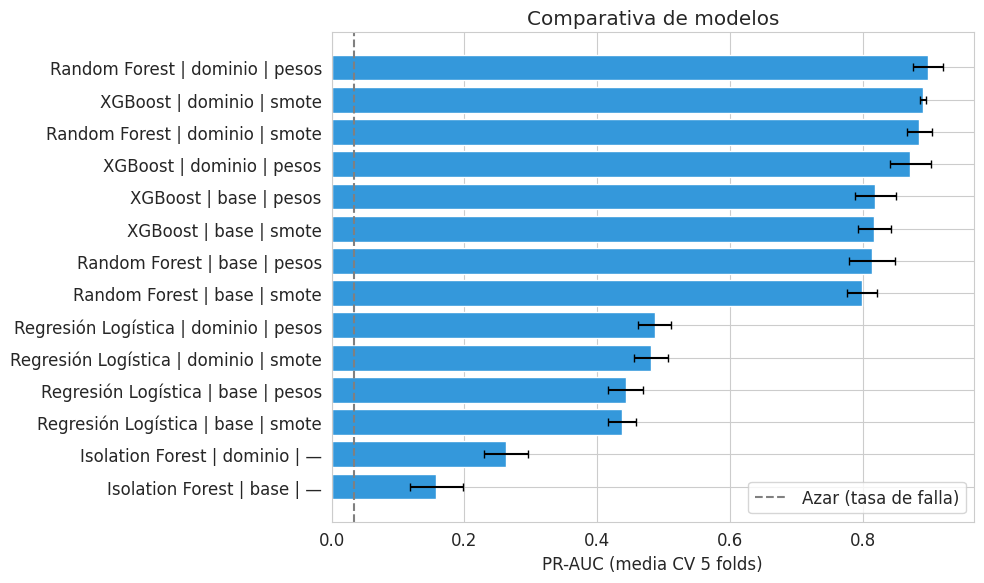

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
etiquetas = tabla['Modelo'] + ' | ' + tabla['Features'] + ' | ' + tabla['Desbalance']
ax.barh(etiquetas[::-1], tabla['pr_auc'][::-1], xerr=tabla['PR-AUC std'][::-1],
        color='#3498db', capsize=3)
ax.axvline(y_train.mean(), color='grey', linestyle='--', label='Azar (tasa de falla)')
ax.set_xlabel('PR-AUC (media CV 5 folds)')
ax.set_title('Comparativa de modelos')
ax.legend()
plt.tight_layout()
plt.show()

### 8.1 Desempate: CV repetida sobre los 4 mejores

Los cuatro primeros quedan dentro de la variación entre folds. Se reevalúan con 5 folds × 3 repeticiones, con semillas distintas a las usadas en el tuning, para reducir el optimismo de haber elegido hiperparámetros con los mismos folds.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
top4 = tabla[tabla['Modelo'] != 'Isolation Forest'].head(4)

desempate = []
for _, row in top4.iterrows():
    key = (row['Modelo'], row['Features'], row['Desbalance'])
    r = cross_validate(clone(mejores[key]), X_train[FEATURES[key[1]]], y_train,
                       cv=rcv, scoring=scoring, n_jobs=-1)
    desempate.append({
        'Modelo': key[0], 'Features': key[1], 'Desbalance': key[2],
        **{m: r[f'test_{m}'].mean() for m in scoring},
        'PR-AUC std': r['test_pr_auc'].std(),
    })

desempate = pd.DataFrame(desempate).sort_values('pr_auc', ascending=False).reset_index(drop=True)
desempate.round(4)

,Modelo,Features,Desbalance,f1,precision,recall,pr_auc,PR-AUC std
0,Random Forest,dominio,pesos,0.8575,0.9499,0.7849,0.8938,0.0298
1,XGBoost,dominio,smote,0.5577,0.4074,0.8930,0.8774,0.0334
2,Random Forest,dominio,smote,0.6553,0.5270,0.8746,0.8735,0.0395
3,XGBoost,dominio,pesos,0.6174,0.4755,0.8907,0.8699,0.0417


## 9. Modelo final y umbral de decisión

**Modelo elegido:** Random Forest con features de dominio y pesos de clase. Fue primero en PR-AUC en las dos evaluaciones (CV del tuning y CV repetida). La diferencia con XGBoost + SMOTE es menor que la variación entre folds, por lo que se prioriza además la simplicidad (sin datos sintéticos).

**Umbral:** el dataset no incluye costos. Se definen escenarios según la relación entre el costo de una falla no detectada (FN) y el de una falsa alarma (FP). Las referencias de la industria indican que una parada no planificada es muy costosa (USD 36.000 a 2,3 millones por hora según el sector; Siemens, *True Cost of Downtime 2024*), pero no hay una relación FN:FP publicada y verificable, por eso se analizan varias.

**Modelo de costos:** cada alerta del modelo (correcta o falsa) cuesta 1 intervención (inspección); cada falla no detectada cuesta la relación elegida (5, 10, 20 o 50 intervenciones).

Los umbrales se eligen con probabilidades *out-of-fold* sobre train. El benchmark es el mantenimiento reactivo: todas las fallas ocurren sin aviso (costo = relación × fallas).

In [ ]:
KEY_FINAL = ('Random Forest', 'dominio', 'pesos')
modelo_final = clone(mejores[KEY_FINAL])
feats_final = FEATURES[KEY_FINAL[1]]

proba_oof = cross_val_predict(modelo_final, X_train[feats_final], y_train,
                              cv=cv, method='predict_proba')[:, 1]

RELACIONES = [5, 10, 20, 50]
umbrales = np.linspace(0.01, 0.99, 99)
yt = y_train.to_numpy()


def costos(umbral, relacion):
    pred = proba_oof >= umbral
    fn = int(((yt == 1) & ~pred).sum())
    fp = int(((yt == 0) & pred).sum())
    alertas = int(pred.sum())
    return fn, fp, relacion * fn + alertas


escenarios = []
for rel in RELACIONES:
    curva = [costos(u, rel)[2] for u in umbrales]
    u_opt = umbrales[int(np.argmin(curva))]
    fn, fp, costo = costos(u_opt, rel)
    tp = int(yt.sum()) - fn
    costo_reactivo = rel * int(yt.sum())
    escenarios.append({
        'Relación FN:FP': f'{rel}:1', 'Umbral': round(u_opt, 2),
        'Recall': tp / yt.sum(), 'Precision': tp / max(tp + fp, 1),
        'Fallas detectadas': tp, 'Fallas no detectadas': fn, 'Falsas alarmas': fp,
        'Ahorro vs reactivo': 1 - costo / costo_reactivo,
    })

escenarios = pd.DataFrame(escenarios)
escenarios.style.format({'Umbral': '{:.2f}', 'Recall': '{:.1%}', 'Precision': '{:.1%}', 'Ahorro vs reactivo': '{:.1%}'})

,Relación FN:FP,Umbral,Recall,Precision,Fallas detectadas,Fallas no detectadas,Falsas alarmas,Ahorro vs reactivo
0,5:1,0.40,83.4%,87.9%,226,45,31,64.4%
1,10:1,0.38,83.8%,85.3%,227,44,39,73.9%
2,20:1,0.10,94.8%,37.8%,257,14,423,82.3%
3,50:1,0.09,95.2%,36.6%,258,13,447,90.0%


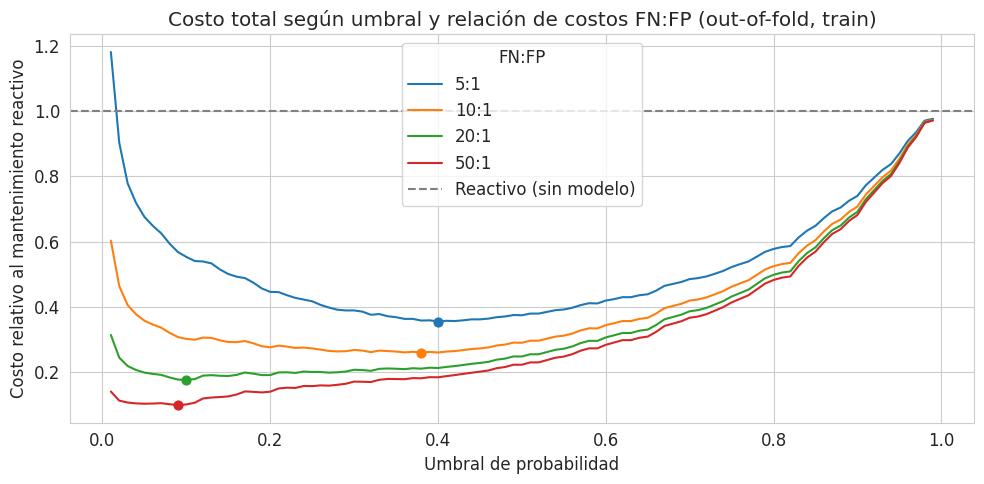

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
for rel in RELACIONES:
    curva = np.array([costos(u, rel)[2] for u in umbrales]) / (rel * yt.sum())
    ax.plot(umbrales, curva, label=f'{rel}:1')
    ax.scatter(umbrales[curva.argmin()], curva.min(), s=40)
ax.axhline(1, color='grey', linestyle='--', label='Reactivo (sin modelo)')
ax.set_xlabel('Umbral de probabilidad')
ax.set_ylabel('Costo relativo al mantenimiento reactivo')
ax.set_title('Costo total según umbral y relación de costos FN:FP (out-of-fold, train)')
ax.legend(title='FN:FP')
plt.tight_layout()
plt.show()

## 10. Evaluación final sobre test

Escenario central: **relación FN:FP de 10:1**, con el umbral elegido en train. El modelo se entrena con todo train y se evalúa **una sola vez** sobre el 20% de test, sin volver a ajustar nada. Los demás escenarios se reportan como análisis de sensibilidad.

Umbral final: 0.38 (escenario 10:1)

PR-AUC:    0.8730
ROC-AUC:   0.9828
F1:        0.8000
Precision: 0.7532
Recall:    0.8529

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1932
       Falla       0.75      0.85      0.80        68

    accuracy                           0.99      2000
   macro avg       0.87      0.92      0.90      2000
weighted avg       0.99      0.99      0.99      2000



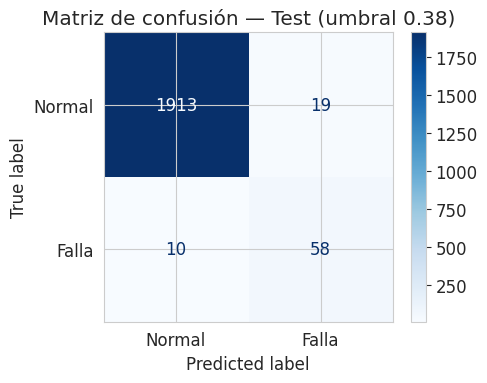

In [ ]:
from sklearn.metrics import roc_auc_score

RELACION_CENTRAL = 10
umbral_final = escenarios.loc[escenarios['Relación FN:FP'] == f'{RELACION_CENTRAL}:1', 'Umbral'].item()

modelo_final.fit(X_train[feats_final], y_train)
proba_test = modelo_final.predict_proba(X_test[feats_final])[:, 1]
pred_test = (proba_test >= umbral_final).astype(int)

print(f"Umbral final: {umbral_final:.2f} (escenario {RELACION_CENTRAL}:1)\n")
print(f"PR-AUC:    {average_precision_score(y_test, proba_test):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, proba_test):.4f}")
print(f"F1:        {f1_score(y_test, pred_test):.4f}")
print(f"Precision: {precision_score(y_test, pred_test):.4f}")
print(f"Recall:    {recall_score(y_test, pred_test):.4f}\n")
print(classification_report(y_test, pred_test, target_names=['Normal', 'Falla']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Normal', 'Falla'],
                                        cmap='Blues', ax=ax)
ax.set_title(f'Matriz de confusión — Test (umbral {umbral_final:.2f})')
plt.tight_layout()
plt.show()

In [ ]:
# Sensibilidad: cada escenario con su umbral elegido en train, medido en test
ytest = y_test.to_numpy()
sens = []
for _, row in escenarios.iterrows():
    rel = int(row['Relación FN:FP'].split(':')[0])
    pred = proba_test >= row['Umbral']
    tp = int(((ytest == 1) & pred).sum())
    fn = int(((ytest == 1) & ~pred).sum())
    fp = int(((ytest == 0) & pred).sum())
    sens.append({
        'Relación FN:FP': row['Relación FN:FP'], 'Umbral': row['Umbral'],
        'Recall': tp / ytest.sum(), 'Precision': tp / max(tp + fp, 1),
        'Fallas detectadas': tp, 'Fallas no detectadas': fn, 'Falsas alarmas': fp,
        'Ahorro vs reactivo': 1 - (rel * fn + tp + fp) / (rel * ytest.sum()),
    })

sens = pd.DataFrame(sens)
sens.style.format({'Umbral': '{:.2f}', 'Recall': '{:.1%}', 'Precision': '{:.1%}',
                   'Ahorro vs reactivo': '{:.1%}'})

,Relación FN:FP,Umbral,Recall,Precision,Fallas detectadas,Fallas no detectadas,Falsas alarmas,Ahorro vs reactivo
0,5:1,0.40,83.8%,78.1%,57,11,16,62.4%
1,10:1,0.38,85.3%,75.3%,58,10,19,74.0%
2,20:1,0.10,92.6%,35.2%,63,5,116,79.5%
3,50:1,0.09,92.6%,33.9%,63,5,123,87.2%


## 11. Importancia de variables (permutación sobre test)

Se mezcla cada variable al azar y se mide cuánto cae la PR-AUC del modelo final en test (20 repeticiones). Cuanto mayor la caída, más depende el modelo de esa variable.

Nota: `Power` se calcula a partir de `Torque` y `Rotational speed`, y `Strain` a partir de `Tool wear` y `Torque`. Las variables correlacionadas se reparten la importancia, así que conviene leerlas en conjunto.

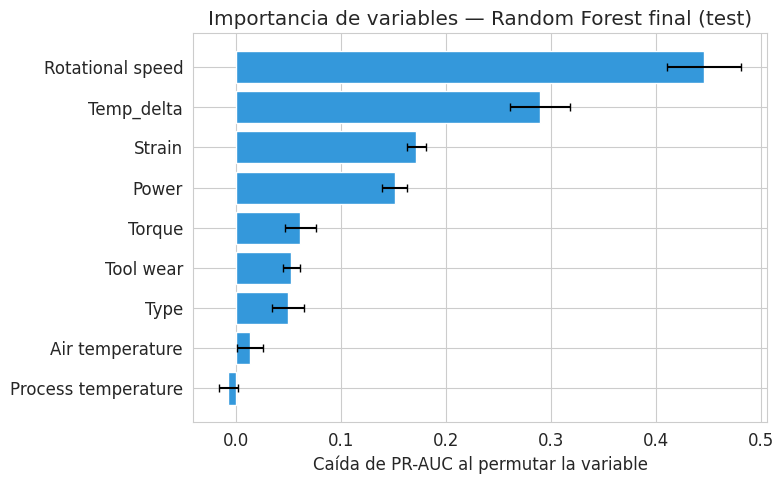

,Variable,Caída PR-AUC,Desvío
0,Rotational speed,0.4457,0.0351
1,Temp_delta,0.2900,0.0285
2,Strain,0.1720,0.0094
3,Power,0.1515,0.0119
4,Torque,0.0616,0.0145
5,Tool wear,0.0529,0.0081
6,Type,0.0499,0.0153
7,Air temperature,0.0141,0.0125
8,Process temperature,-0.0069,0.0088


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test[feats_final], y_test,
                              scoring='average_precision', n_repeats=20,
                              random_state=SEED, n_jobs=-1)

importancia = (pd.DataFrame({'Variable': feats_final,
                             'Caída PR-AUC': perm.importances_mean,
                             'Desvío': perm.importances_std})
               .sort_values('Caída PR-AUC', ascending=False)
               .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancia['Variable'][::-1], importancia['Caída PR-AUC'][::-1],
        xerr=importancia['Desvío'][::-1], color='#3498db', capsize=3)
ax.set_xlabel('Caída de PR-AUC al permutar la variable')
ax.set_title('Importancia de variables — Random Forest final (test)')
plt.tight_layout()
plt.show()

importancia.round(4)

**Interpretación.** Las variables más importantes corresponden a los mecanismos de falla documentados para el dataset:

| Variables | Modo de falla |
|---|---|
| Rotational speed + Temp_delta | Disipación de calor (HDF): baja diferencia de temperatura con baja velocidad |
| Power | Potencia (PWF): potencia fuera de rango |
| Strain + Type | Sobrecarga (OSF): desgaste × torque sobre un límite que depende de la calidad |
| Tool wear | Desgaste de herramienta (TWF) |

Las temperaturas por separado casi no aportan: importa su diferencia, lo que justifica la variable Temp_delta.

**Limitación:** el dataset es sintético y el modelo aprende las reglas con que se generaron las fallas. Con datos reales habría que validar que estos patrones se mantienen.

## 12. Consideraciones éticas y de privacidad

**Datos:** AI4I 2020 es sintético y tiene licencia CC BY 4.0, que permite usarlo citando la fuente. No contiene datos personales, por lo que no aplica la Ley 25.326 de Protección de Datos Personales.

**Riesgos en un despliegue real y mitigaciones:**

1. **Vigilancia laboral:** los datos de las máquinas pueden vincularse a operarios o turnos. Mitigación: analizar por máquina y no por persona, e informar a los trabajadores.
2. **Sesgo de automatización:** riesgo de confiar ciegamente en las alertas. Mitigación: el modelo da apoyo y el técnico decide; no reemplaza los protocolos de seguridad.
3. **Fallas no detectadas (15%):** son un riesgo para la seguridad. Mitigación: mantener las inspecciones programadas como respaldo.
4. **Generalización:** el modelo se entrenó con datos sintéticos. Mitigación: validarlo con datos reales antes de usarlo en producción.
5. **Transparencia:** el umbral y las variables importantes quedan documentados (secciones 9 y 11).